# Notebook 6.4 — L2-selected patch sensitivity: a candidate vs Baseline A

**Background.** Baseline A sets the rejection bar per voxel, `S_j = max_i |D_ij|` — the largest leave-one-out
influence at voxel *j* across subjects. Different voxels can be set by different subjects, so the bar is a
coordinatewise envelope, not a profile any single subject actually produces.

This notebook tests one change, requested after the supervisor meeting: pick the **single subject with the
largest whole-patch L2 influence**, `i* = argmax_i ||D_i||₂`, and use that subject's per-voxel `|D_{i*}|` as the
bar. *Only the sensitivity vector changes* — the covariance construction, the per-voxel rejection rule
(`|Z_j| ≥ S_j` for every *j*) and the independent fallback are Baseline A's, reused verbatim: the candidate
just wraps the frozen mechanism and swaps the bar it is handed. Baseline A itself is untouched and is the
reference throughout.

*Noise scale — intrinsic.* We run the mechanism at **its own scale**, not an external power budget. Its noise
covariance has two parts: the **correlation** from `Cov(LOO)` (loo_corr) or `Cov(data)` (data_corr), and a
**per-voxel SD `= 2·std(D_j)/ε`** (ε=1 here) — twice the standard deviation of voxel *j*'s LOO perturbations,
so the noise is sensitivity-scaled by design. This is the mechanism's actual behaviour, so the wall we see here
is the *real* wall. (An earlier draft power-matched the noise to a fraction of signal variance for comparability
with notebook 6; that inflated the noise ~50× on the mean and erased the wall — a comparison artifact, not the
mechanism. The factor `2` and `ε` are the real scale knobs; we sweep them deliberately in a later noise-vs-utility
study, not here.)

*Statistics.* `data_corr` and `loo_corr` are structurally identical for the **mean**, so the source axis only
does something for **non-linear** statistics; we therefore run mean, median and variance. *Recaps assume
notebooks 4–5, 6, 6.1, 6.3.*

Four questions: **(A)** how different are the two bars, and what does the L2 bar leave uncovered? **(B)** does
it ease the wall, and what does it cost in privacy *and* utility, across statistics? **(C)** *why* does the
privacy effect move the way it does — accepted noise or fallback noise? **(D)** sweeping `p` up from the low-dim
regime, where does the wall begin, how much does the `k_sigma` target inflate it, and how much noise would
break it?

In [1]:
import sys, os, numpy as np, pandas as pd, matplotlib.pyplot as plt
from matplotlib.lines import Line2D
for cand in [".", "harness", os.path.expanduser("~/harness")]:
    if os.path.exists(os.path.join(cand, "privacy_harness.py")): sys.path.insert(0, cand); break
import privacy_harness as ph
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": .3})
PAL = {"A": "#4c72b0", "L2": "#c44e52"}
PIPES = {"mean": ph.pipeline_mean, "median": ph.pipeline_median, "variance": ph.pipeline_variance}

# --- the candidate: the two-line change, wrapped around the frozen mechanism ---
def l2_selected_bar(D):
    A = D.reshape(D.shape[0], -1)                        # (N, p) LOO perturbations
    istar = int(np.argmax(np.linalg.norm(A, axis=1)))   # subject with largest whole-patch L2 influence
    return np.abs(A[istar]), istar                      # |D_{i*}|, per voxel (flattened)
def l2_bar(base_mech):                                  # reuse Baseline A's mechanism, only swap the bar
    def m(y, D, S, **kw): return base_mech(y, D, l2_selected_bar(D)[0].reshape(S.shape), **kw)
    return m

# --- substrate: OASIS blocks when available, else a synthetic stand-in (executed outputs are synthetic) ---
USE_OASIS = True                                        # set True where nilearn + network are available
N = 40
note = None
def make_source(bs):
    global note
    if USE_OASIS:
        try:
            src = ph.oasis_source(n=max(N, 60), block_shape=bs, N=N, seed=0)
            note = "OASIS gray-matter maps"; return src
        except Exception as e:
            note = f"synthetic (OASIS unavailable: {e})"
    note = note or "synthetic stand-in"
    return ph.SyntheticBlockSource(N=N, block_shape=bs, spatial_corr=0.8, base_std=1.0)

A_mech  = {"data_corr": ph.mech_supervisor_data_corr(), "loo_corr": ph.mech_supervisor_loo_corr()}
L2_mech = {"data_corr": l2_bar(ph.mech_supervisor_data_corr()),
           "loo_corr":  l2_bar(ph.mech_supervisor_loo_corr())}
_ = make_source((4, 4, 4))                              # sets `note`
print(f"SUBSTRATE: {note}   (USE_OASIS={USE_OASIS}, N={N})")
print("ready")

SUBSTRATE: synthetic (OASIS unavailable: No module named 'nilearn')   (USE_OASIS=True, N=40)
ready


## A — How different are the two bars, and what does L2 leave uncovered?

One patch, one cohort, the mean pipeline. **Left/middle:** the per-voxel max bar (A) vs the L2-selected bar
`|D_{i*}|`, voxel by voxel. **Right (the cost):** for each voxel where the L2 bar sits *below* A's, how far
below — `100·(A − L2)/A` — a histogram over those voxels. A covers every subject at every voxel by
construction; L2 does not, and this shows by how much, and how many subjects slip above it.

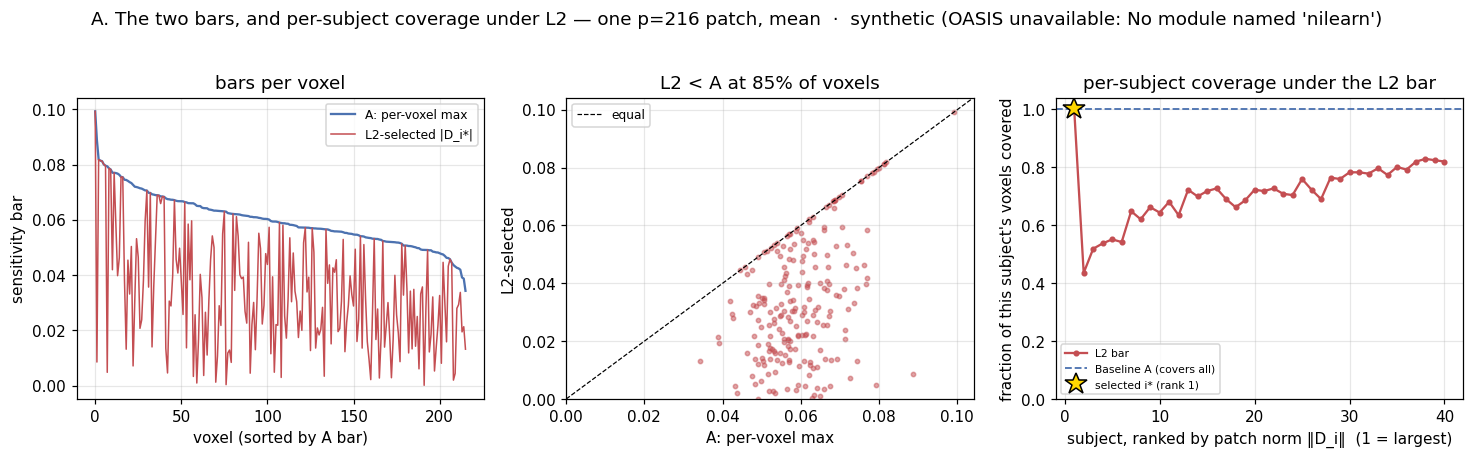

AUTO-SUMMARY (synthetic (OASIS unavailable: No module named 'nilearn')):
  selected subject i* = 30 (rank 1 by patch norm); its profile IS the L2 bar.
  L2 total bar is 43% lower than A's; L2 < A at 85% of voxels.
  coverage: Baseline A covers 100% of subject-voxel influences by construction; L2 covers 71.1% overall,
  with median per-subject coverage 72% and 39 of 40 subjects below 100%.


In [2]:
bs_A = (6, 6, 6)
srcA = make_source(bs_A)
y, D, S_max = ph.loo_artifacts(srcA.sample(N, np.random.default_rng(0)), ph.pipeline_mean)
S_max = S_max.reshape(-1); absD = np.abs(D.reshape(N, -1))
S_l2, istar = l2_selected_bar(D)

under = S_l2 < S_max - 1e-12                                  # voxels where L2 bar is below the true max
shortfall = (S_max[under] - S_l2[under]) / (S_max[under] + 1e-12)   # fractional gap at those voxels
uncovered = absD > S_l2[None, :] + 1e-12                      # (subject, voxel) influences above the L2 bar
frac_uncovered = float(uncovered.mean())                     # A leaves 0% uncovered by construction
subj_exceed = int(uncovered.any(1).sum())                    # distinct subjects poking above the L2 bar

fig, ax = plt.subplots(1, 3, figsize=(13.5, 4))
order = np.argsort(S_max)[::-1]
ax[0].plot(S_max[order], color=PAL["A"], label="A: per-voxel max")
ax[0].plot(S_l2[order], color=PAL["L2"], lw=1, label="L2-selected |D_i*|")
ax[0].set_xlabel("voxel (sorted by A bar)"); ax[0].set_ylabel("sensitivity bar")
ax[0].set_title("bars per voxel"); ax[0].legend(fontsize=8)
lim = [0, float(S_max.max()) * 1.05]
ax[1].scatter(S_max, S_l2, s=8, alpha=.5, color=PAL["L2"]); ax[1].plot(lim, lim, "k--", lw=.8, label="equal")
ax[1].set_xlim(lim); ax[1].set_ylim(lim); ax[1].set_xlabel("A: per-voxel max"); ax[1].set_ylabel("L2-selected")
ax[1].set_title(f"L2 < A at {under.mean():.0%} of voxels"); ax[1].legend(fontsize=8)
# panel 3: per-subject coverage — fraction of each subject's voxels the L2 bar covers (|D_ij| <= bar_j).
# Baseline A (per-voxel max) covers everyone everywhere -> flat at 100%. i* is fully covered (it IS the bar).
cover = (absD <= S_l2[None, :] + 1e-12).mean(1)               # (N,) per-subject coverage fraction
norms = np.linalg.norm(absD, axis=1)                          # per-subject patch norm ||D_i||
order_sub = np.argsort(norms)[::-1]                           # subjects ranked by patch norm, largest first
istar_rank = int(np.where(order_sub == istar)[0][0]) + 1
ax[2].plot(range(1, N + 1), cover[order_sub], "o-", ms=3, color=PAL["L2"], label="L2 bar")
ax[2].axhline(1.0, color=PAL["A"], ls="--", lw=1.2, label="Baseline A (covers all)")
ax[2].plot(istar_rank, cover[istar], "*", ms=15, color="gold", mec="k", zorder=5, label=f"selected i* (rank {istar_rank})")
ax[2].set_ylim(0, 1.04); ax[2].set_xlabel("subject, ranked by patch norm ‖D_i‖  (1 = largest)")
ax[2].set_ylabel("fraction of this subject's voxels covered")
ax[2].set_title("per-subject coverage under the L2 bar"); ax[2].legend(fontsize=7, loc="lower left")
fig.suptitle(f"A. The two bars, and per-subject coverage under L2 — one p={int(np.prod(bs_A))} patch, mean  ·  {note}", y=1.03)
plt.tight_layout(); plt.show()
print(f"AUTO-SUMMARY ({note}):")
print(f"  selected subject i* = {istar} (rank 1 by patch norm); its profile IS the L2 bar.")
print(f"  L2 total bar is {100*(1-S_l2.sum()/S_max.sum()):.0f}% lower than A's; L2 < A at {under.mean():.0%} of voxels.")
print(f"  coverage: Baseline A covers 100% of subject-voxel influences by construction; "
      f"L2 covers {100*(1-frac_uncovered):.1f}% overall,")
print(f"  with median per-subject coverage {np.median(cover):.0%} and {int((cover < 0.999).sum())} of {N} subjects below 100%.")

**Read-off (A).** *"Covered" means the bar is ≥ a subject's influence at a voxel.* Baseline A's bar is the
per-voxel maximum, so it covers **every** subject at **every** voxel — its curve sits flat at 100% (dashed line).
The L2 bar is one subject's profile: the selected subject *i\** is fully covered (the star at 100%), but the
other subjects dip below, typically more so the larger their own patch norm — the very subjects most at risk are
the least covered. The gap between the dashed A line and the L2 curve is the price of moving from a coordinatewise
worst case to a single realizable profile: a group/L2 sensitivity, not a per-voxel worst case. The auto-summary
gives this run's coverage figures; non-linear statistics have heavier-tailed influence, so the gap generally
widens there.

## B — Easing the wall vs the cost in privacy and utility, across statistics

The membership game for A vs the L2 candidate, both correlation sources, across patch sizes, **for mean, median
and variance**, at the **intrinsic scale**, averaged over seeds with the spread shown. One row per statistic;
four columns: **fallback** (does the lower bar ease the wall?), **privacy** (advantage `TPR − FPR`, leakage
lower-bound), **utility: rel-MSE**, and **utility: bias** (`bias_norm`, the systematic shift rejection adds).
For the mean the two sources coincide; for median and variance they separate — that separation is the
covariance-source effect the earlier notebooks flagged, now under the L2 vs A comparison. Color = bar (A vs L2);
linestyle = source (data solid, loo dashed), with a small x-offset so coincident lines stay visible.

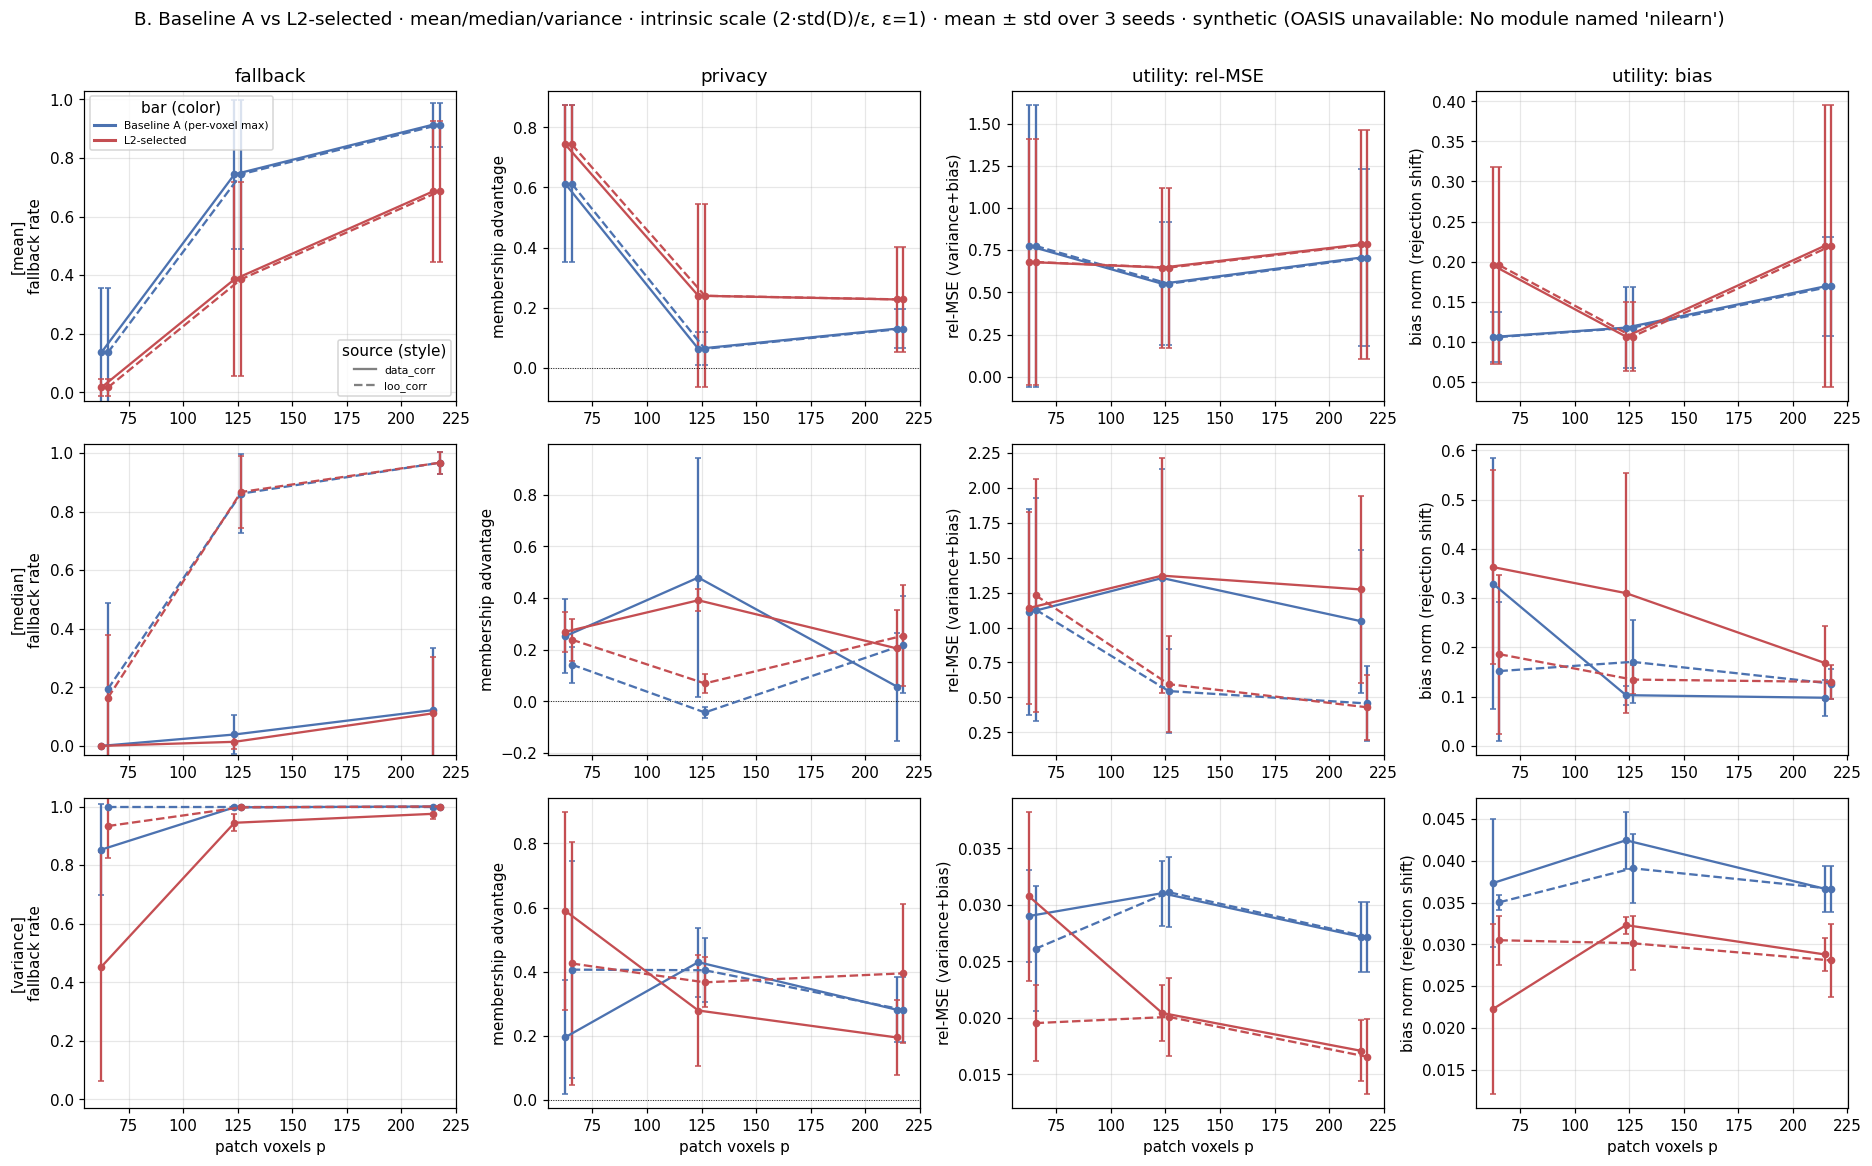

                            fallback  advantage  rel_mse  bias_norm  spearman  neighbour_corr_gap
pipeline p   source    bar                                                                       
mean     64  data_corr A       0.136      0.613    0.775      0.106     0.883               0.035
                       L2      0.017      0.743    0.680      0.196     0.918               0.025
             loo_corr  A       0.136      0.613    0.775      0.106     0.883               0.035
                       L2      0.017      0.743    0.680      0.196     0.918               0.025
         125 data_corr A       0.744      0.064    0.551      0.118     0.770               0.186
                       L2      0.386      0.240    0.647      0.107     0.857               0.108
             loo_corr  A       0.744      0.064    0.551      0.118     0.770               0.186
                       L2      0.386      0.240    0.647      0.107     0.857               0.108
         216 data_co

In [3]:
SIZES = [(4, 4, 4), (5, 5, 5), (6, 6, 6)]
SEEDS = [0, 1, 2]
N_TRIALS, N_REL = 200, 20
sources_cache = {bs: make_source(bs) for bs in SIZES}
rows = []
for pipe_name, pipe in PIPES.items():
    for bs in SIZES:
        src = sources_cache[bs]; p = int(np.prod(bs))
        for source in ["data_corr", "loo_corr"]:
            for label, mech in [("A", A_mech[source]), ("L2", L2_mech[source])]:
                for sd in SEEDS:
                    r = ph.evaluate(src, pipe, mech, N=N, noise_power=None,   # intrinsic scale (2*std(D)/eps)
                                    n_trials=N_TRIALS, n_rel=N_REL, seed=sd)
                    rows.append({"pipeline": pipe_name, "p": p, "source": source, "bar": label,
                                 "seed": sd, "advantage": r["empirical_adv"], "fallback": r["fallback_rate"],
                                 "rel_mse": r["rel_mse"], "bias_norm": r["bias_norm"],
                                 "spearman": r["spearman"], "neighbour_corr_gap": r["neighbour_corr_gap"]})
df = pd.DataFrame(rows)
g = df.groupby(["pipeline", "p", "source", "bar"]).agg(["mean", "std"]).reset_index()

# utility is more than rel-MSE: bias_norm isolates the systematic shift that rejection introduces
metrics = [("fallback", "fallback rate", (-.03, 1.03)), ("advantage", "membership advantage", None),
           ("rel_mse", "rel-MSE (variance+bias)", None), ("bias_norm", "bias norm (rejection shift)", None)]
COL_TITLES = ["fallback", "privacy", "utility: rel-MSE", "utility: bias"]
SRC_LS = {"data_corr": "-", "loo_corr": "--"}; SRC_DX = {"data_corr": -1.5, "loo_corr": 1.5}
pipes_order = list(PIPES)
fig, axes = plt.subplots(len(pipes_order), 4, figsize=(17, 3.5 * len(pipes_order)), squeeze=False)
for ri, pipe_name in enumerate(pipes_order):
    for a, (col, ylab, ylim) in zip(axes[ri], metrics):
        for label in ["A", "L2"]:
            for source in ["data_corr", "loo_corr"]:
                d = g[(g.pipeline == pipe_name) & (g.source == source) & (g.bar == label)].sort_values("p")
                a.errorbar(d["p"] + SRC_DX[source], d[(col, "mean")], yerr=d[(col, "std")],
                           ls=SRC_LS[source], marker="o", ms=4, capsize=2, color=PAL[label])
        if ylim: a.set_ylim(*ylim)
        if col == "advantage": a.axhline(0, color="k", lw=.6, ls=":")   # advantage=0 reference (negatives = noise)
        a.set_ylabel(ylab)
    axes[ri][0].set_ylabel(f"[{pipe_name}]\n{metrics[0][1]}")
for a in axes[-1]: a.set_xlabel("patch voxels p")
for a, t in zip(axes[0], COL_TITLES): a.set_title(t)
leg_bar = [Line2D([0],[0], color=PAL["A"], lw=2, label="Baseline A (per-voxel max)"),
           Line2D([0],[0], color=PAL["L2"], lw=2, label="L2-selected")]
leg_src = [Line2D([0],[0], color="grey", ls="-", lw=1.5, label="data_corr"),
           Line2D([0],[0], color="grey", ls="--", lw=1.5, label="loo_corr")]
l1 = axes[0][0].legend(handles=leg_bar, fontsize=7, loc="upper left", title="bar (color)")
axes[0][0].add_artist(l1); axes[0][0].legend(handles=leg_src, fontsize=7, loc="lower right", title="source (style)")
fig.suptitle(f"B. Baseline A vs L2-selected · mean/median/variance · intrinsic scale (2·std(D)/ε, ε=1) "
             f"· mean ± std over {len(SEEDS)} seeds · {note}", y=1.005)
plt.tight_layout(); plt.show()
print(df.groupby(["pipeline", "p", "source", "bar"])[
    ["fallback", "advantage", "rel_mse", "bias_norm", "spearman", "neighbour_corr_gap"]].mean().round(3).to_string())
print(f"\nAUTO-SUMMARY ({note}) — loo_corr branch:")
for pn in pipes_order:
    sub = df[(df.pipeline == pn) & (df.source == "loo_corr")]
    fbA = sub[sub.bar == "A"].groupby("p")["fallback"].mean()
    onset = fbA.index[fbA > 0.5]; onset = int(onset.min()) if len(onset) else None
    dfb = (fbA - sub[sub.bar == "L2"].groupby("p")["fallback"].mean()).mean()
    advA, advL = sub[sub.bar == "A"]["advantage"].mean(), sub[sub.bar == "L2"]["advantage"].mean()
    print(f"  {pn:8s}: A wall (fallback>0.5) {('from p='+str(onset)) if onset else 'not reached in grid'}; "
          f"L2 lowers fallback by {dfb:+.0%} on avg; mean advantage A={advA:+.2f}, L2={advL:+.2f}")

**Read-off (B).** Read each statistic's row on its own. **Fallback** is the wall — watch *where* it
climbs with `p` and on *which branch*: the non-linear statistics on the `loo_corr` side are expected to wall
first, while the mean and the `data_corr` branches clear more easily (the loo-covariance correlation is what
fails to cover the bar). **Privacy** (advantage, with the 0-line; negatives are sampling noise) — only clearly
positive values are real leakage, and the question is whether L2 moves it up or down vs A. **Utility** is split:
`rel-MSE` mixes variance and bias and is *not* comparable across statistics (it is normalized by the signal's own
energy, tiny for the mean), while **bias norm** isolates the systematic shift rejection adds — expect it to track
fallback, since a walled config is biased, not merely noisier. The auto-summary and table carry this run's
numbers; the colour contrast (A vs L2) at each `p` is the comparison that matters. Part C dissects *why* the
advantage moves where a wall exists.

## C — Why does the privacy effect move that way? Accept vs fallback

Each released patch is either an **accepted** correlated draw (noise cleared the bar) or a **fallback**
independent draw (`_tail_normal`). Lowering the bar changes both the *mix* and the accepted noise *size*. To see
which path carries the membership signal, build the two worlds, draw many releases tagging each by path, fit the
same held-out linear attacker on all of them, then read its advantage **separately on accepted vs fallback
releases**, with each path's mean noise power. The decomposition only means something where the mechanism
*actually* falls back some of the time, so the cell **picks the configuration (statistic, source, `p`) whose
Baseline-A fallback is nearest 50%** from the Part B sweep — on synthetic that is a non-linear statistic (the
mean does not wall here on synthetic); on OASIS it is the mean. Intrinsic scale throughout.

Part C configs (loo_corr; p chosen for partial A-fallback): {'mean': 'p=125, A-fallback=74%', 'median': 'p=64, A-fallback=19%', 'variance': 'p=216, A-fallback=100%'}


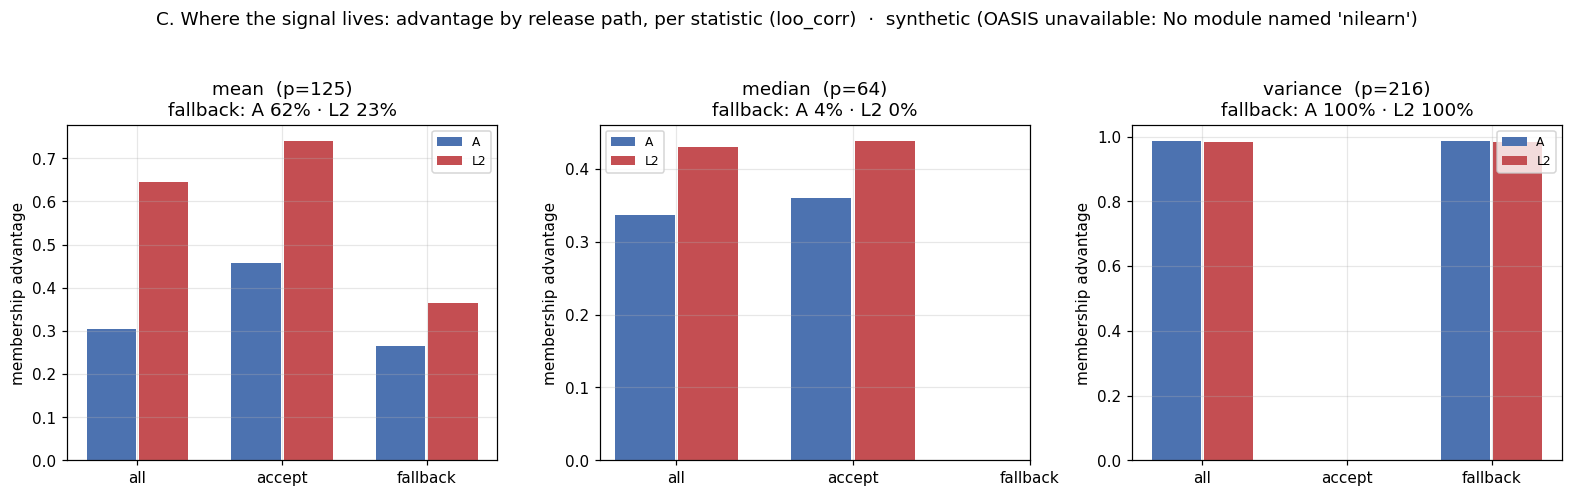

              fallback_frac  adv_all  adv_accept  adv_fallback  pow_accept  pow_fallback
pipeline bar                                                                            
mean     A            0.620    0.304       0.458         0.265       2.986         1.198
         L2           0.233    0.645       0.741         0.364       2.562         1.010
median   A            0.044    0.337       0.360           NaN       4.388         1.279
         L2           0.005    0.430       0.439           NaN       4.120         1.137
variance A            1.000    0.987         NaN         0.987         NaN         8.617
         L2           0.999    0.985         NaN         0.985      11.642         6.033

AUTO-SUMMARY (synthetic (OASIS unavailable: No module named 'nilearn')):
  mean    : fallback 62%; advantage accept > fallback (accept +0.46 vs fallback +0.27; power accept 3.0 vs fallback 1.2)
  median  : all accepted (no fallback) — decomposition degenerate at this config (p=64)
  var

In [4]:
def path_decomp(src, mech, pipe, n=800, seed=0, k=2.0):
    rng = np.random.default_rng(seed)
    pool = src.sample(N, rng); background = src.sample(N - 1, rng)
    target = ph.target_ksigma(pool, k)
    g_in, g_out, m_in, m_out = ph._worlds(src, N, pipe, background, target, None, mech, {})  # intrinsic scale
    def draw(model, g, lab):
        X, fb, pw = [], [], []
        for _ in range(n):
            z, f = model._s(rng)                      # raw sampler -> (noise, fell_back)
            X.append(g + z); fb.append(bool(f)); pw.append(float(z @ z))
        return np.array(X), np.array(fb), np.array(pw), np.full(n, lab)
    Xo, fo, po, yo = draw(m_out, g_out, 0); Xi, fi, pi, yi = draw(m_in, g_in, 1)
    X = np.vstack([Xo, Xi]); fb = np.r_[fo, fi]; pw = np.r_[po, pi]; yb = np.r_[yo, yi]
    idx = rng.permutation(len(X)); X, fb, pw, yb = X[idx], fb[idx], pw[idx], yb[idx]
    cut = len(X) // 2
    w = ph._lda_dir(X[:cut], yb[:cut]); thr = ph._threshold_youden(X[:cut] @ w, yb[:cut])
    s, yt, fbt = X[cut:] @ w, yb[cut:], fb[cut:]
    def adv(mask):
        return ph._adv_at(s[mask], yt[mask], thr) if (mask.sum() > 30 and len(np.unique(yt[mask])) == 2) else np.nan
    return {"fallback_frac": float(fb.mean()), "adv_all": ph._adv_at(s, yt, thr),
            "adv_accept": adv(~fbt), "adv_fallback": adv(fbt),
            "pow_accept": float(pw[~fb].mean()) if (~fb).any() else np.nan,
            "pow_fallback": float(pw[fb].mean()) if fb.any() else np.nan}

# Run the decomposition for ALL THREE statistics (they wall differently). For each, pick — from the Part B
# sweep — the p whose Baseline-A fallback is nearest 0.5 (so accept vs fallback is comparable); if that
# statistic never walls on this substrate (e.g. the mean on synthetic), use the largest p and flag it: with
# ~no fallback the fallback bar is absent by construction, which is itself the honest read. loo_corr throughout
# (it is the branch that walls); on OASIS the mean walls too.
SRC_C = "loo_corr"
res = {}; chosen = {}
for pipe_name in pipes_order:
    cand = df[(df.bar == "A") & (df.pipeline == pipe_name) & (df.source == SRC_C)] \
             .groupby("p")["fallback"].mean()
    band = cand[(cand > 0.1) & (cand < 0.97)]
    p_pick = int((band - 0.5).abs().idxmin()) if len(band) else int(cand.index.max())
    chosen[pipe_name] = (p_pick, float(cand.loc[p_pick]))
    bs = next(b for b in SIZES if int(np.prod(b)) == p_pick)
    src = sources_cache[bs]
    for label, mech in [("A", A_mech[SRC_C]), ("L2", L2_mech[SRC_C])]:
        res[(pipe_name, label)] = path_decomp(src, mech, PIPES[pipe_name], seed=0)
print("Part C configs (loo_corr; p chosen for partial A-fallback):",
      {k: f"p={v[0]}, A-fallback={v[1]:.0%}" for k, v in chosen.items()})

tbl = pd.DataFrame(res).T
tbl.index = pd.MultiIndex.from_tuples(tbl.index, names=["pipeline", "bar"])
xlab = ["all", "accept", "fallback"]; xx = np.arange(3)
fig, ax = plt.subplots(1, len(pipes_order), figsize=(4.8 * len(pipes_order), 4.3), squeeze=False); ax = ax[0]
for a, pipe_name in zip(ax, pipes_order):
    p_pick = chosen[pipe_name][0]
    for off, label in [(-0.18, "A"), (0.18, "L2")]:
        r = res[(pipe_name, label)]
        a.bar(xx + off, [r["adv_all"], r["adv_accept"], r["adv_fallback"]], 0.34, color=PAL[label], label=label)
    a.axhline(0, color="k", lw=.6, ls=":")
    a.set_xticks(xx); a.set_xticklabels(xlab); a.set_ylabel("membership advantage")
    a.set_title(f"{pipe_name}  (p={p_pick})\nfallback: A {res[(pipe_name,'A')]['fallback_frac']:.0%}"
                f" · L2 {res[(pipe_name,'L2')]['fallback_frac']:.0%}")
    a.legend(fontsize=8)
fig.suptitle(f"C. Where the signal lives: advantage by release path, per statistic (loo_corr)  ·  {note}", y=1.04)
plt.tight_layout(); plt.show()
print(tbl.round(3).to_string())
print(f"\nAUTO-SUMMARY ({note}):")
for pn in pipes_order:
    rA = res[(pn, "A")]
    if np.isfinite(rA["adv_accept"]) and np.isfinite(rA["adv_fallback"]):
        order = "accept > fallback" if rA["adv_accept"] > rA["adv_fallback"] else "fallback ≥ accept"
        print(f"  {pn:8s}: fallback {rA['fallback_frac']:.0%}; advantage {order} "
              f"(accept {rA['adv_accept']:+.2f} vs fallback {rA['adv_fallback']:+.2f}; "
              f"power accept {rA['pow_accept']:.1f} vs fallback {rA['pow_fallback']:.1f})")
    else:
        why = "all accepted (no fallback)" if rA["fallback_frac"] < 0.05 else "near-total fallback (no accepted draws)"
        print(f"  {pn:8s}: {why} — decomposition degenerate at this config (p={chosen[pn][0]})")

**Read-off (C).** The decomposition is only readable in the *transition band* (partial fallback); the
auto-summary flags which statistics are there and which are degenerate (all-accept before the wall, all-fallback
past it). Where both paths exist, the question is whether the **accepted (correlated)** path leaks more than the
**fallback (independent)** path *despite carrying more power*. If it does, that is notebook 6.1's mechanism —
correlated noise fills the high-variance modes and leaves the membership direction exposed, while the independent
fallback covers it more evenly — and it means lowering the bar, which shifts mass toward accepted draws, works
*against* privacy. Read the ordering and the per-path powers in the auto-summary for this run's substrate.

## D — Where does the wall begin, and how much noise breaks it?

Parts B–C start at `p=64`; notebooks 4–5 ran at `p=2–3` with no trouble. This part sweeps `p` **upward from the
low-dim regime** to locate where the rejection wall actually sets in, and separates two effects:

- **D1 — wall onset, and how much the target inflates it.** The fallback rate is read from the noise model built
  on the stack that *includes the target subject*, so the target is one of the `N` subjects that set the bar
  `S = max_i|D_ij|`. The default `k_sigma` target is a synthetic subject +2 SD above the mean at *every* voxel at
  once — it inflates the bar and so the wall. We plot fallback vs `p` for `{A, L2} × {k_sigma, actual}` at the
  mechanism's default scale (factor 2, ε=1), to see the real onset and how much is a `k_sigma` artifact.
- **D2 — how much noise would break the wall.** The scale is `SD = 2·std(D)/ε`, so sweeping "how many SDs" is
  sweeping ε: factor `= 2/ε`, giving ε ∈ {1, 0.5, ⅓, 0.25} for factors {2, 4, 6, 8}. The bar is *not* rescaled, so
  more noise clears it more often. Baseline A, both targets.

Fallback only (no attacker/utility), via a lightweight probe (build the mechanism, draw `n_rel` samples, read the
fallback rate), parallelised over patch size with `joblib`. Intrinsic scale, `loo_corr`, 3 seeds.

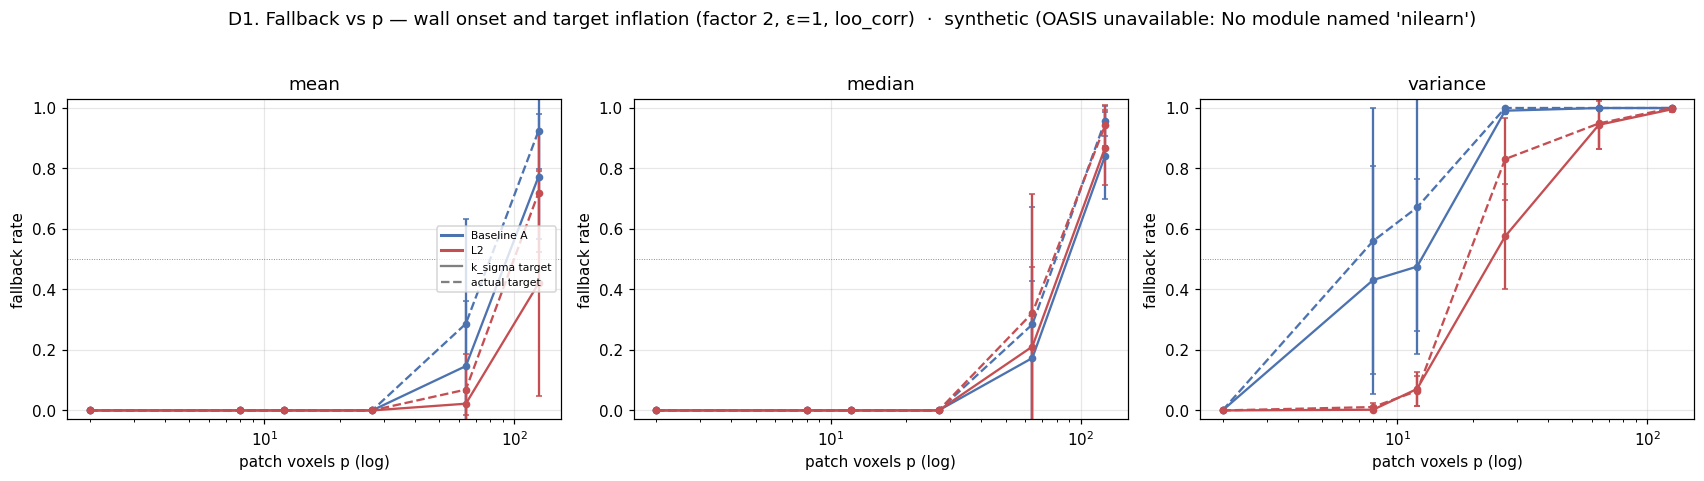

AUTO-SUMMARY (synthetic (OASIS unavailable: No module named 'nilearn')) — D1, wall onset (first p with fallback>0.5), Baseline A:
  mean    : k_sigma wall p=125;  actual wall p=125
  median  : k_sigma wall p=125;  actual wall p=125
  variance: k_sigma wall p=27;  actual wall p=8


In [5]:
from joblib import Parallel, delayed

P_GRID   = [(1, 1, 2), (2, 2, 2), (2, 2, 3), (3, 3, 3), (4, 4, 4), (5, 5, 5)]   # p = 2, 8, 12, 27, 64, 125
D_SEEDS  = (0, 1, 2); D_NREL = 150; FACTORS = (2, 4, 6, 8); TARGETS = ("k_sigma", "actual")

def sweep_one_bs(bs, N=40, n_rel=150, seeds=(0, 1, 2), factors=(2, 4, 6, 8),
                 targets=("k_sigma", "actual"), use_oasis=True):
    """Self-contained (picklable) fallback sweep for one patch shape. Fallback only — no attacker."""
    import sys, os, numpy as np
    for cand in [".", "harness", os.path.expanduser("~/harness")]:
        if os.path.exists(os.path.join(cand, "privacy_harness.py")): sys.path.insert(0, cand); break
    import privacy_harness as ph
    pipes = {"mean": ph.pipeline_mean, "median": ph.pipeline_median, "variance": ph.pipeline_variance}
    def l2bar(base):
        def m(y, D, S, **kw):
            A = D.reshape(D.shape[0], -1); istar = int(np.argmax(np.linalg.norm(A, axis=1)))
            return base(y, D, np.abs(A[istar]).reshape(S.shape), **kw)
        return m
    src = None
    if use_oasis:
        try: src = ph.oasis_source(n=max(N, 60), block_shape=bs, N=N, seed=0)
        except Exception: src = None
    if src is None:
        src = ph.SyntheticBlockSource(N=N, block_shape=bs, spatial_corr=0.8, base_std=1.0)
    is_oasis = type(src).__name__ == "ArrayBlockSource"
    p = int(np.prod(bs)); eps = {f: 2.0 / f for f in factors}; out = []
    for pn, pipe in pipes.items():
        for tm in targets:
            for seed in seeds:
                rng = np.random.default_rng(seed)
                pool = src.sample(N, rng); background = src.sample(N - 1, rng)
                target = ph.target_ksigma(pool, 2.0) if tm == "k_sigma" else pool[0]
                stack = np.vstack([background, target]).reshape(N, *bs)
                y, D, S = ph.loo_artifacts(stack, pipe); subj = stack.reshape(N, -1)
                for f in factors:                                   # Baseline A across scale factors
                    model = ph.mech_supervisor_loo_corr(epsilon=eps[f])(y, D, S, noise_power=None, subjects=subj)
                    r2 = np.random.default_rng(1000 + seed)
                    for _ in range(n_rel): model.sample(r2)
                    out.append(dict(pipeline=pn, p=p, bar="A", target=tm, factor=f, seed=seed,
                                    fallback=model.fallback_rate))
                modelL = l2bar(ph.mech_supervisor_loo_corr(epsilon=eps[2]))(y, D, S, noise_power=None, subjects=subj)
                r3 = np.random.default_rng(2000 + seed)             # L2 at factor 2 only
                for _ in range(n_rel): modelL.sample(r3)
                out.append(dict(pipeline=pn, p=p, bar="L2", target=tm, factor=2, seed=seed,
                                fallback=modelL.fallback_rate))
    return out, is_oasis

_res = Parallel(n_jobs=-1, backend="loky")(
    delayed(sweep_one_bs)(bs, N=N, n_rel=D_NREL, seeds=D_SEEDS, factors=FACTORS,
                          targets=TARGETS, use_oasis=USE_OASIS) for bs in P_GRID)
df_D = pd.DataFrame([r for sub, _ in _res for r in sub])
note_D = ("OASIS gray-matter maps" if all(o for _, o in _res) else note)
gD = df_D.groupby(["pipeline", "p", "bar", "target", "factor"])["fallback"].agg(["mean", "std"]).reset_index()

# D1: fallback vs p, {A,L2} x {k_sigma, actual}, at factor 2 (default scale)
TGT_LS = {"k_sigma": "-", "actual": "--"}
d1 = gD[gD.factor == 2]
fig, ax = plt.subplots(1, len(pipes_order), figsize=(5.2 * len(pipes_order), 4.2), squeeze=False); ax = ax[0]
for a, pn in zip(ax, pipes_order):
    for bar in ["A", "L2"]:
        for tgt in TARGETS:
            d = d1[(d1.pipeline == pn) & (d1.bar == bar) & (d1.target == tgt)].sort_values("p")
            a.errorbar(d["p"], d["mean"], yerr=d["std"], ls=TGT_LS[tgt], marker="o", ms=4,
                       capsize=2, color=PAL[bar])
    a.axhline(0.5, color="grey", lw=.6, ls=":"); a.set_xscale("log")
    a.set_ylim(-.03, 1.03); a.set_xlabel("patch voxels p (log)"); a.set_ylabel("fallback rate")
    a.set_title(pn)
leg = [Line2D([0],[0], color=PAL["A"], lw=2, label="Baseline A"), Line2D([0],[0], color=PAL["L2"], lw=2, label="L2"),
       Line2D([0],[0], color="grey", ls="-", label="k_sigma target"), Line2D([0],[0], color="grey", ls="--", label="actual target")]
ax[0].legend(handles=leg, fontsize=7, loc="center right")
fig.suptitle(f"D1. Fallback vs p — wall onset and target inflation (factor 2, ε=1, loo_corr)  ·  {note_D}", y=1.03)
plt.tight_layout(); plt.show()
print(f"AUTO-SUMMARY ({note_D}) — D1, wall onset (first p with fallback>0.5), Baseline A:")
for pn in pipes_order:
    def onset(tgt):
        s = gD[(gD.pipeline == pn) & (gD.bar == "A") & (gD.target == tgt) & (gD.factor == 2)].set_index("p")["mean"]
        hit = s.index[s > 0.5]; return int(hit.min()) if len(hit) else None
    ok, oa = onset("k_sigma"), onset("actual")
    print(f"  {pn:8s}: k_sigma wall {('p='+str(ok)) if ok else '>max'};  actual wall {('p='+str(oa)) if oa else '>max'}"
          + (f"  → k_sigma inflates the wall to {ok}× earlier dimensions" if (ok and oa and ok < oa) else ""))

**Read-off (D1).** Two things to read. First, the **onset**: find the `p` where fallback crosses the
0.5 line — that is where the wall begins, and the log-`p` axis shows whether it is near the `p=2–3` of notebooks
4–5 or far above it. Second, the **target gap**: the `k_sigma` curves (solid) sit above the `actual` curves
(dashed) by however much the extreme synthetic target inflates the bar; if the solid curve walls much earlier
than the dashed one, a large part of the "high fallback at low p" is a `k_sigma` artifact, not the mechanism on
realistic data. A vs L2 (colour) shows whether the grouped bar delays onset. The auto-summary reports each
target's onset `p` for this run.

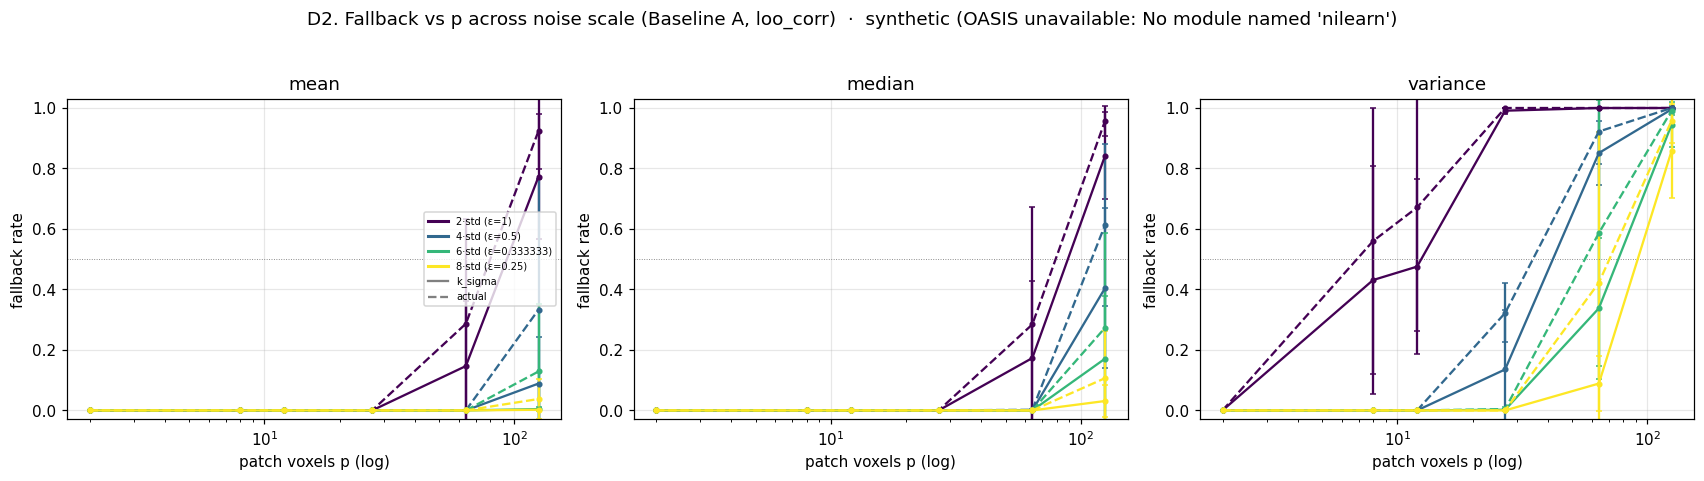

AUTO-SUMMARY (synthetic (OASIS unavailable: No module named 'nilearn')) — D2, smallest factor that keeps fallback<0.5 at the largest p (125):
  mean     [k_sigma]: needs 4·std to drop below 0.5 fallback at p=125
  mean     [actual ]: needs 4·std to drop below 0.5 fallback at p=125
  median   [k_sigma]: needs 4·std to drop below 0.5 fallback at p=125
  median   [actual ]: needs 6·std to drop below 0.5 fallback at p=125
  variance [k_sigma]: needs >8·std (still 86% at 8·std) to drop below 0.5 fallback at p=125
  variance [actual ]: needs >8·std (still 96% at 8·std) to drop below 0.5 fallback at p=125


In [6]:
# D2: how much noise breaks the wall — fallback vs p for scale factors {2,4,6,8}, Baseline A, both targets
import matplotlib.cm as cm
FAC_COL = {f: cm.viridis(i / (len(FACTORS) - 1)) for i, f in enumerate(FACTORS)}
fig, ax = plt.subplots(1, len(pipes_order), figsize=(5.2 * len(pipes_order), 4.2), squeeze=False); ax = ax[0]
for a, pn in zip(ax, pipes_order):
    for f in FACTORS:
        for tgt in TARGETS:
            d = gD[(gD.pipeline == pn) & (gD.bar == "A") & (gD.factor == f) & (gD.target == tgt)].sort_values("p")
            a.errorbar(d["p"], d["mean"], yerr=d["std"], ls=TGT_LS[tgt], marker="o", ms=3,
                       capsize=2, color=FAC_COL[f])
    a.axhline(0.5, color="grey", lw=.6, ls=":"); a.set_xscale("log")
    a.set_ylim(-.03, 1.03); a.set_xlabel("patch voxels p (log)"); a.set_ylabel("fallback rate"); a.set_title(pn)
leg = [Line2D([0],[0], color=FAC_COL[f], lw=2, label=f"{f}·std (ε={2/f:g})") for f in FACTORS] + \
      [Line2D([0],[0], color="grey", ls="-", label="k_sigma"), Line2D([0],[0], color="grey", ls="--", label="actual")]
ax[0].legend(handles=leg, fontsize=6.5, loc="center right")
fig.suptitle(f"D2. Fallback vs p across noise scale (Baseline A, loo_corr)  ·  {note_D}", y=1.03)
plt.tight_layout(); plt.show()
print(f"AUTO-SUMMARY ({note_D}) — D2, smallest factor that keeps fallback<0.5 at the largest p ({max(df_D.p)}):")
pmax = int(max(df_D.p))
for pn in pipes_order:
    for tgt in TARGETS:
        s = gD[(gD.pipeline == pn) & (gD.bar == "A") & (gD.p == pmax) & (gD.target == tgt)].set_index("factor")["mean"]
        ok = [f for f in FACTORS if s.get(f, 1) < 0.5]
        got = f"{min(ok)}·std" if ok else f">8·std (still {s.get(max(FACTORS), float('nan')):.0%} at 8·std)"
        print(f"  {pn:8s} [{tgt:7s}]: needs {got} to drop below 0.5 fallback at p={pmax}")

**Read-off (D2).** Each colour is a noise scale (how many SDs); within a colour, solid/dashed is the
target. Reading down a column at fixed `p`, more noise (lighter colour) lowers fallback — the question is *how
much* is needed to get below the 0.5 line at each `p`, and whether any feasible scale (≤ 8·std) clears the wall
at the larger patches. If even 8·std cannot, the wall is not a scale problem — it is structural, and easing it
costs utility that grows with the factor (the deliberate noise-vs-utility study will price that). The
auto-summary reports, per statistic and target, the smallest factor that clears the wall at the largest `p`.

## Decisions & open questions

- **Keep-or-drop is an OASIS decision.** The L2 bar eases fallback; whether that buys utility without an
  unacceptable advantage cost, and *why* the advantage moves (Part C), must be read on real OASIS — then decided
  with the supervisor. Only then would it fold into the reference (a deliberate un-freezing of Baseline A). Until
  then it stays a candidate beside A.
- **Scale is the mechanism's own (intrinsic `2·std(D)/ε`), not an external budget.** The wall shown here is the
  real one. An earlier draft power-matched noise to signal variance for comparability with notebook 6; that
  inflated noise ~50× on the mean, destroyed utility (rel-MSE > 1) and erased the wall — a comparison artifact.
  Notebook 6's "wall at p≈64" should be re-read as a property of that `rel=0.125` budget, not the mechanism.
- **Noise-scale vs *fallback* is now mapped (Part D2); utility is still deferred.** D2 sweeps the scale
  (factor `= 2/ε`, {2,4,6,8}·std) and shows how much noise clears the wall. The missing half — what that noise
  costs in *utility* (and privacy) — is the deliberate frontier study still to do.
- **Target inflates the wall (Part D1).** Fallback is read with the target in the stack, so the extreme
  `k_sigma` target raises the bar and the wall; D1 separates that from the realistic `actual` target. An
  outlier-brain target (a real atypical subject) is the parked middle ground.
- **Utility is more than rel-MSE.** Report `bias_norm` (rejection shift), `spearman` and `neighbour_corr_gap`
  (structure) alongside it; and scientific utility (Type-I/power via `inference_eval`) is a separate question.
- **What the change weakens (Part A).** No longer a per-voxel worst case — only the L2-selected subject's
  profile is dominated everywhere; a measurable slice of subject-voxel influences is left uncovered. A group/L2
  sensitivity; report it as such.
- **Acceptance rule unchanged.** Still `|Z_j| ≥ S_j` for all *j*; only the sensitivity vector changed.
- **Deferred — tiling.** Brain tiling (size, stride, overlap) and the per-patch selected-subject distribution
  are a separate study.
- **Next:** rerun on OASIS (all parts); the median/variance rows are where the covariance-source axis and the
  heavy-tailed-sensitivity effect should be sharpest.